# 04 · Objetivo (iv): menções à inteligência artificial generativa

> *"Identificar menções à IA generativa e ao uso de suas ferramentas, distinguindo requisitos profissionais, atividades previstas e referências ao contexto organizacional."* (Seção 1.3, objetivo iv)

**Perguntas**
1. Com que frequência a IA generativa é mencionada, por grupo, nível, área e portal?
2. Que termos aparecem (ChatGPT, Copilot, LLM, prompt...)?
3. Em que **papel** ela aparece: requisito, atividade ou contexto da empresa? Há associação com **revisão/validação** dos resultados?
4. Anúncios **com** e **sem** menção diferem nas demais competências, **depois de padronizar por tamanho do texto** e restringir a Desenvolvimento e dados sem a área IA (Seção 3.5)?

**Ligação com a literatura:** Westby et al. (2026) — menções explícitas a IA/ML caíram nas vagas júnior remanescentes; Chen et al. (2024) — recrutadores valorizam proficiência com IA, mas 65% das organizações não tinham diretrizes; Brynjolfsson et al. (2025) — aprendizagem com assistência de IA.

> **Definição operacional (Seção 3.4-b):** anúncio com menção à IA generativa = a taxonomia do projeto identificou **"Copilots e assistentes de IA"** (GitHub Copilot, ChatGPT, Claude Code, Cursor...) ou **"LLMs e IA generativa"** (LLMs, engenharia de prompts, APIs de modelos).
> A classificação em *requisito / atividade / contexto* é feita aqui por **regras automáticas apenas como pré-classificação**: a classificação definitiva do artigo é manual (`ia_trechos_para_classificacao_manual.csv`).
> Nada neste notebook mede **efeito** da IA nos requisitos; a comparação com × sem é de associação em corte transversal.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
from sklearn.metrics import cohen_kappa_score
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 220)
df = L.carregar()
dev = df[(df.grupo == L.G_DEV) & (df.area != "Inteligência Artificial")].copy()
CHAVES = list(L.COMPETENCIAS); ROT = {k: v[1] for k, v in L.COMPETENCIAS.items()}
print(f"Base total: {len(df):,} | Desenvolvimento e dados sem a área IA (recorte da comparação): {len(dev):,} | com menção a IA generativa: {dev.genai.sum():,} ({dev.genai.mean():.1%})")

Base total: 9,964 | Desenvolvimento e dados sem a área IA (recorte da comparação): 3,738 | com menção a IA generativa: 417 (11.2%)


## 1. Prevalência da menção à IA generativa

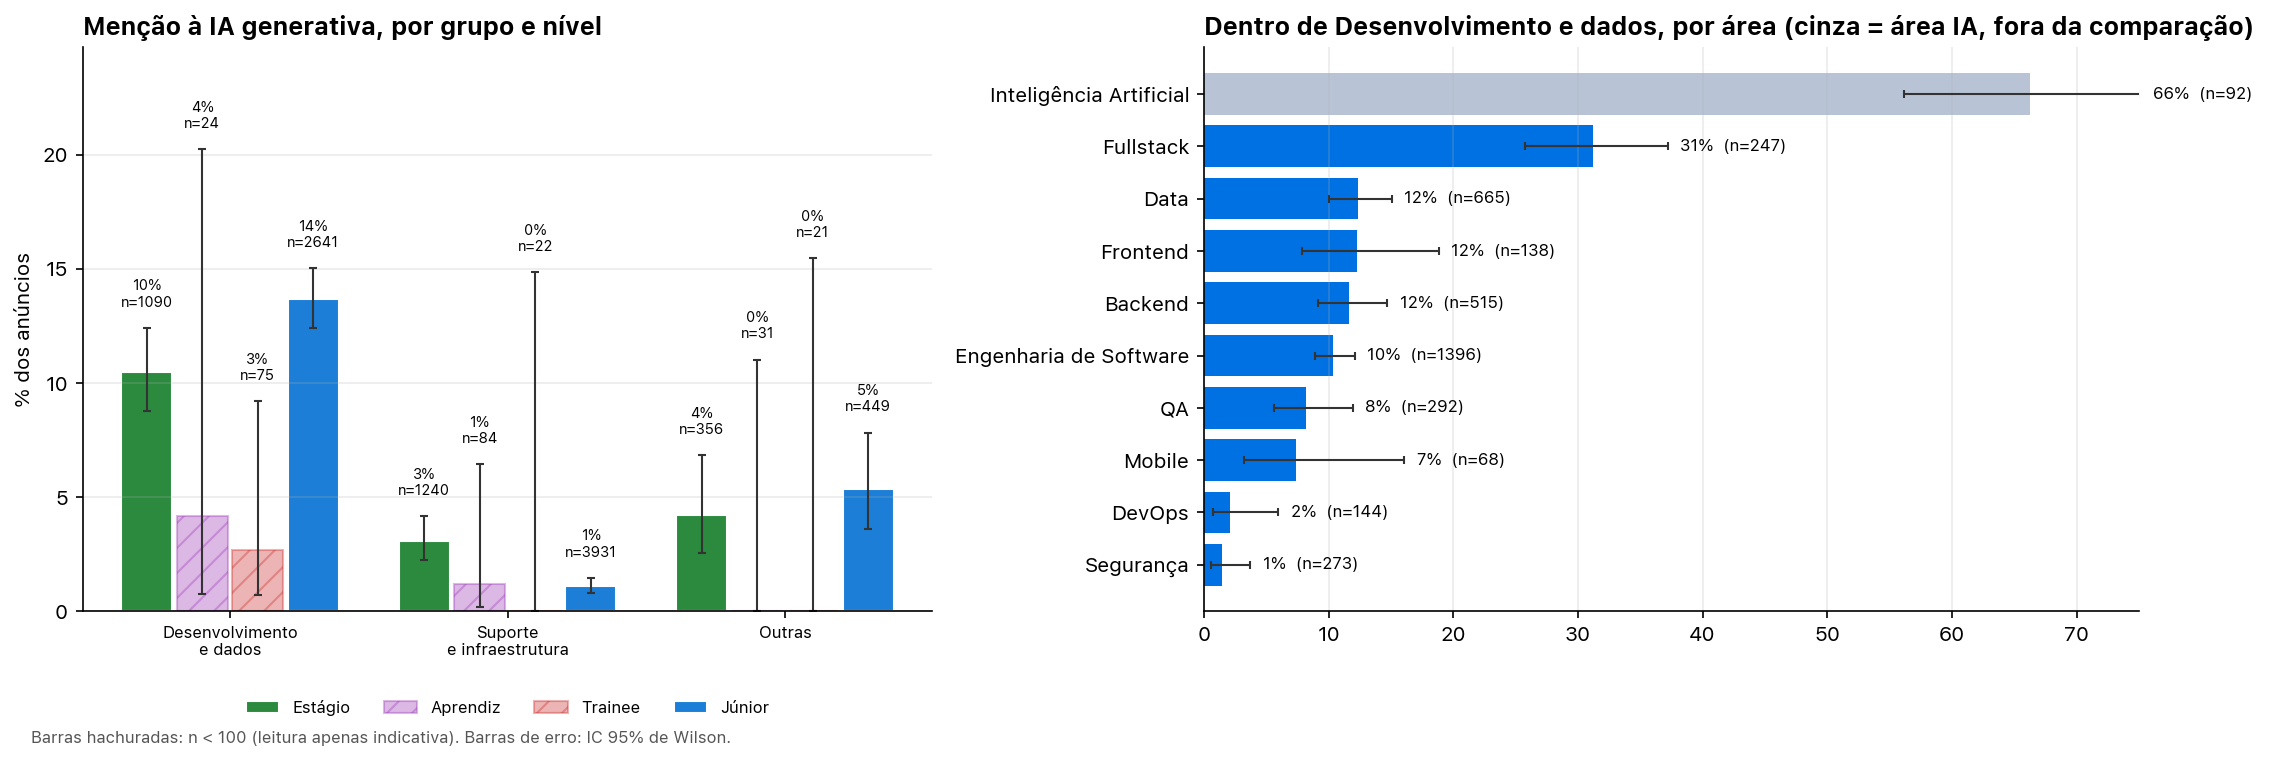

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
t = L.tabela_prop(df, "genai", ["grupo", "nivel"])
L.barras_prop(axes[0], t, "grupo", "nivel", L.ORDEM_GRUPOS, L.ORDEM_NIVEIS, L.PALETA_NIVEL)
axes[0].set_title("Menção à IA generativa, por grupo e nível"); axes[0].set_xticklabels([g.replace(" e ", "\ne ") for g in L.ORDEM_GRUPOS], fontsize=8)
ta = L.tabela_prop(df[df.grupo == L.G_DEV], "genai", ["area"]); ta = ta[ta["n"] >= 40].sort_values("pct")
cores = ["#B8C4D6" if a == "Inteligência Artificial" else L.PALETA[L.G_DEV] for a in ta["area"].astype(str)]
axes[1].barh(ta["area"].astype(str), ta["pct"], color=cores, xerr=[ta["pct"] - ta["ic_lo"], ta["ic_hi"] - ta["pct"]], error_kw=dict(ecolor="#333", lw=1, capsize=2))
for i, (_, r) in enumerate(ta.iterrows()): axes[1].text(r["ic_hi"] + 1, i, f"{r['pct']:.0f}%  (n={int(r['n'])})", va="center", fontsize=8)
axes[1].set_title("Dentro de Desenvolvimento e dados, por área (cinza = área IA, fora da comparação)"); axes[1].set_xlim(0, 75); axes[1].grid(axis="y", visible=False)
L.nota_n_pequeno(fig); L.salvar(fig, "04_prevalencia_ia"); plt.show()

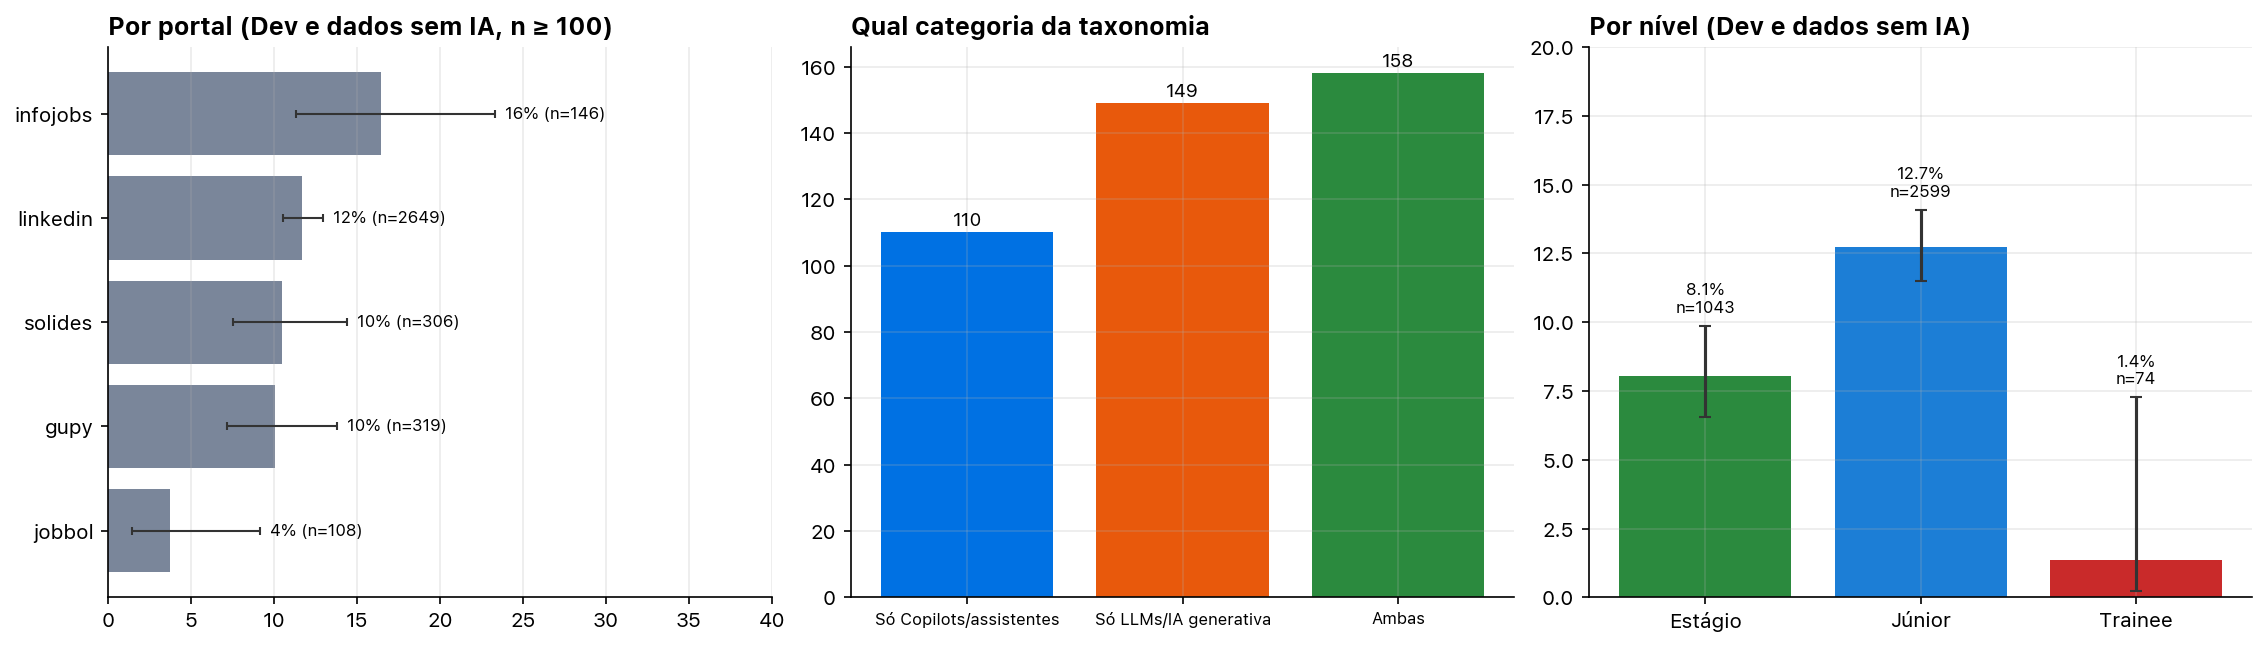

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# por portal
tp = L.tabela_prop(dev, "fonte", ["fonte"]) if False else None
tp = L.tabela_prop(dev, "genai", ["fonte"]); tp = tp[tp["n"] >= 100].sort_values("pct")
axes[0].barh(tp["fonte"], tp["pct"], color="#7A869A", xerr=[tp["pct"] - tp["ic_lo"], tp["ic_hi"] - tp["pct"]], error_kw=dict(ecolor="#333", lw=1, capsize=2))
for i, (_, r) in enumerate(tp.iterrows()): axes[0].text(r["ic_hi"] + .6, i, f"{r['pct']:.0f}% (n={int(r['n'])})", va="center", fontsize=8)
axes[0].set_title("Por portal (Dev e dados sem IA, n ≥ 100)"); axes[0].grid(axis="y", visible=False); axes[0].set_xlim(0, 40)
# copilot x llm
k = pd.crosstab(dev.sk_copilot, dev.sk_llm)
parts = {"Só Copilots/assistentes": k.loc[True, False], "Só LLMs/IA generativa": k.loc[False, True], "Ambas": k.loc[True, True]}
axes[1].bar(parts.keys(), parts.values(), color=["#0071E3", "#E8590C", "#2B8A3E"])
for i, v_ in enumerate(parts.values()): axes[1].text(i, v_ + 2, str(v_), ha="center", fontsize=9)
axes[1].set_title("Qual categoria da taxonomia"); axes[1].tick_params(axis="x", labelsize=8)
# nivel
tn = L.tabela_prop(dev, "genai", ["nivel"]); tn = tn[tn["n"] >= 40]
axes[2].bar(tn["nivel"], tn["pct"], color=[L.PALETA_NIVEL[n] for n in tn["nivel"]], yerr=[tn["pct"] - tn["ic_lo"], tn["ic_hi"] - tn["pct"]], error_kw=dict(ecolor="#333", capsize=3))
for i, (_, r) in enumerate(tn.iterrows()): axes[2].text(i, r["ic_hi"] + .5, f"{r['pct']:.1f}%\nn={int(r['n'])}", ha="center", fontsize=8)
axes[2].set_title("Por nível (Dev e dados sem IA)"); axes[2].set_ylim(0, 20)
L.salvar(fig, "04_ia_portal_categoria_nivel"); plt.show()

Os portais divergem bastante, o que reforça a necessidade da sensibilidade por portal no notebook `06`.

## 2. Que termos aparecem?
Busca textual, nos anúncios marcados pela taxonomia (Dev e dados sem IA), dos termos mais comuns. A taxonomia pode ter reconhecido termos fora desta lista.

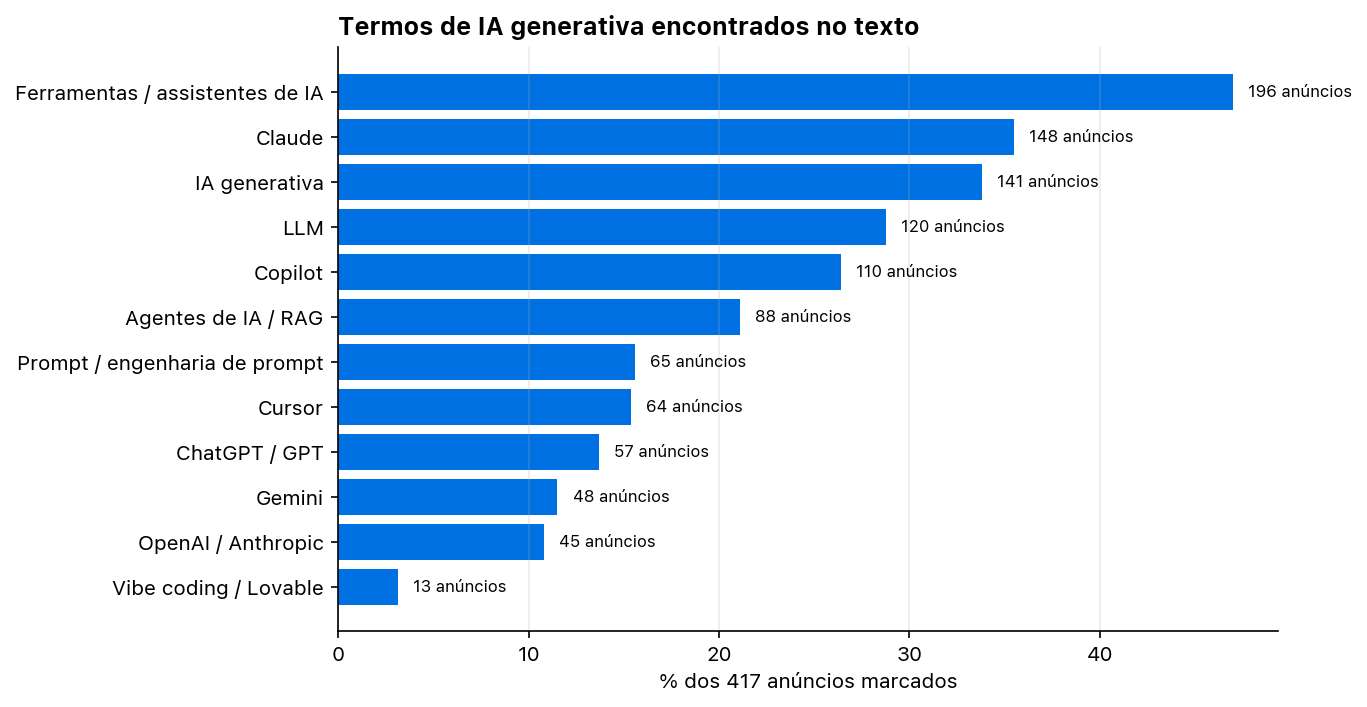

Anúncios marcados pela taxonomia sem nenhum termo desta lista: 5 (1%)


In [4]:
TERMOS = {"ChatGPT / GPT": r"chat ?gpt|\bgpt[- ]?\d?\b", "Copilot": r"copilot", "Claude": r"claude", "Cursor": r"cursor\b|windsurf", "Gemini": r"gemini",
          "LLM": r"\bllms?\b|grandes modelos|modelos de linguagem", "IA generativa": r"ia generativa|inteligencia artificial generativa|genai|gen ai",
          "Prompt / engenharia de prompt": r"prompt\w*", "OpenAI / Anthropic": r"openai|anthropic", "Agentes de IA / RAG": r"agentes? de (ia|inteligencia)|\brag\b|langchain",
          "Ferramentas / assistentes de IA": r"ferramentas? de (ia|inteligencia artificial)|assistentes? de (ia|codigo)", "Vibe coding / Lovable": r"vibe coding|lovable"}
fl = dev[dev.genai]
contagem = {nome: fl["tf"].str.contains(rx).sum() for nome, rx in TERMOS.items()}
sem_termo = (~fl["tf"].str.contains("|".join(TERMOS.values()))).sum()
s = pd.Series(contagem).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(s.index, s.values / len(fl) * 100, color="#0071E3")
for i, v_ in enumerate(s.values): ax.text(v_ / len(fl) * 100 + .8, i, f"{v_} anúncios", va="center", fontsize=8)
ax.set_xlabel(f"% dos {len(fl)} anúncios marcados"); ax.set_title("Termos de IA generativa encontrados no texto"); ax.grid(axis="y", visible=False)
L.salvar(fig, "04_termos_ia"); plt.show()
print(f"Anúncios marcados pela taxonomia sem nenhum termo desta lista: {sem_termo} ({sem_termo / len(fl):.0%})")

## 3. Papel da menção: pré-classificação automática dos trechos

Para cada anúncio marcado em Dev e dados (sem IA), localiza-se a **primeira menção** e se aplica:
1. **Contexto organizacional (C):** o trecho está sob título de "sobre a empresa/quem somos" ou tem marcas de fala institucional (*"somos", "nossa plataforma", "utilizamos"*).
2. **Atividade prevista (A):** o trecho está sob "responsabilidades/atividades".
3. **Requisito profissional (R):** sob "requisitos/diferenciais" ou perto de *"conhecimento, experiência, familiaridade, desejável"*.
4. **Indefinido:** o resto, para leitura humana.

Também registra se há palavras de **revisão/validação** perto da menção (*revisar, validar, avaliar, verificar, supervisionar...*).
**São regras simples. A classificação final é a manual.**

Planilha salva: ia_trechos_para_classificacao_manual.csv (417 trechos)


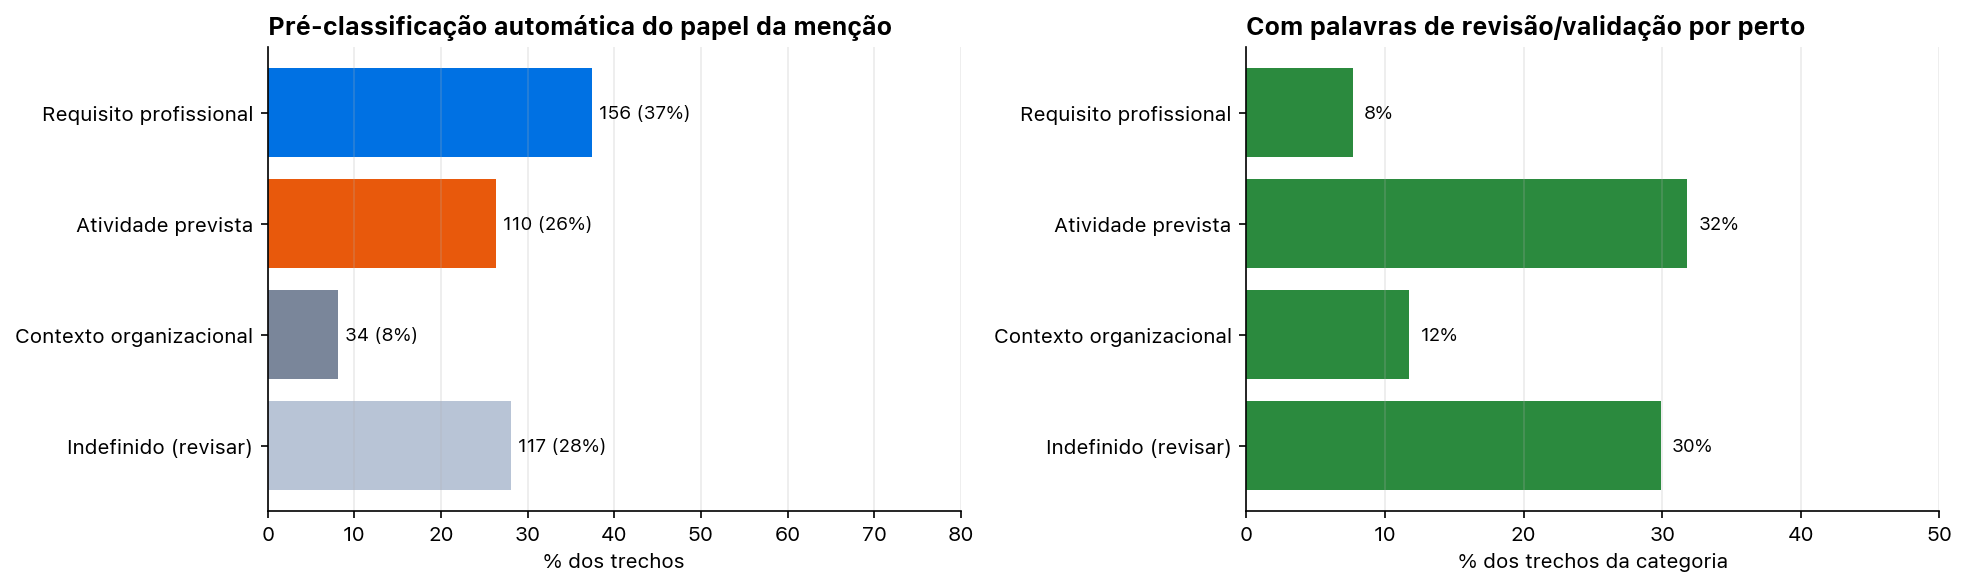

Trechos com palavras de revisão/validação por perto (geral): 21%


In [5]:
RX_SEM_BARE = re.compile(L.GENAI_TERMOS.replace(r"|\bia\b", ""))
RX_BARE = re.compile(r"\bia\b|inteligencia artificial")

def secao_proxima(tf, texto, pos):
    melhor = (-1, None)
    for nome, rx in (("R", L._TIT_REQ), ("A", L._TIT_ATV), ("C", L._TIT_EMP)):
        for m in rx.finditer(tf, 0, pos):
            if L._eh_titulo(texto, m.start(), m.end()) and m.start() > melhor[0]:
                melhor = (m.start(), nome)
    return melhor[1]

def pre_classificar(tf, texto, ini, fim):
    janela = tf[max(0, ini - 150): fim + 150]
    sec = secao_proxima(tf, texto, ini)
    if sec == "C" or L._CTX_EMPRESA.search(janela):
        return "Contexto organizacional"
    if sec == "A":
        return "Atividade prevista"
    if sec == "R" or L._CTX_REQ.search(tf[max(0, ini - 80): ini + 30]):
        return "Requisito profissional"
    return "Indefinido (revisar)"

linhas = []
for _, r in fl.iterrows():
    m = RX_SEM_BARE.search(r["tf"]) or RX_BARE.search(r["tf"])
    if not m:
        linhas.append({"id_anuncio": f"{r['fonte']}:{r['external_id']}", "area": r["area"], "nivel": r["nivel"], "fonte": r["fonte"], "url": r["url"],
                       "termo": "(não localizado)", "trecho": "", "pre_classificacao_automatica": "Indefinido (revisar)", "assoc_validacao_automatica": False})
        continue
    janela_val = r["tf"][max(0, m.start() - 200): m.end() + 200]
    linhas.append({"id_anuncio": f"{r['fonte']}:{r['external_id']}", "area": r["area"], "nivel": r["nivel"], "fonte": r["fonte"], "url": r["url"],
                   "termo": r["texto"][m.start():m.end()], "trecho": L.trecho(r["texto"], m.start(), m.end(), 220),
                   "pre_classificacao_automatica": pre_classificar(r["tf"], r["texto"], m.start(), m.end()),
                   "assoc_validacao_automatica": bool(L._CTX_VALID.search(janela_val))})
ia = pd.DataFrame(linhas)
ia["categoria_manual_leitora1 (R/A/C)"] = ""; ia["categoria_manual_leitora2 (R/A/C)"] = ""; ia["associa_revisao_validacao_manual (sim/nao)"] = ""; ia["observacao"] = ""
ia.to_csv(L.BASE / "ia_trechos_para_classificacao_manual.csv", index=False, encoding="utf-8-sig")
print(f"Planilha salva: ia_trechos_para_classificacao_manual.csv ({len(ia)} trechos)")

ordem = ["Requisito profissional", "Atividade prevista", "Contexto organizacional", "Indefinido (revisar)"]
d1 = ia["pre_classificacao_automatica"].value_counts().reindex(ordem, fill_value=0)
d2 = ia.groupby("pre_classificacao_automatica")["assoc_validacao_automatica"].mean().reindex(ordem).fillna(0) * 100
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].barh(d1.index[::-1], d1.values[::-1] / len(ia) * 100, color=["#B8C4D6", "#7A869A", "#E8590C", "#0071E3"])
for i, v_ in enumerate(d1.values[::-1]): axes[0].text(v_ / len(ia) * 100 + .8, i, f"{v_} ({v_ / len(ia):.0%})", va="center", fontsize=9)
axes[0].set_title("Pré-classificação automática do papel da menção"); axes[0].set_xlim(0, 80); axes[0].grid(axis="y", visible=False); axes[0].set_xlabel("% dos trechos")
axes[1].barh(d2.index[::-1], d2.values[::-1], color="#2B8A3E")
for i, v_ in enumerate(d2.values[::-1]): axes[1].text(v_ + .8, i, f"{v_:.0f}%", va="center", fontsize=9)
axes[1].set_title("Com palavras de revisão/validação por perto"); axes[1].set_xlim(0, 50); axes[1].grid(axis="y", visible=False); axes[1].set_xlabel("% dos trechos da categoria")
L.salvar(fig, "04_papel_mencao"); plt.show()
print(f"Trechos com palavras de revisão/validação por perto (geral): {ia.assoc_validacao_automatica.mean():.0%}")

### Amostra para conferir a pré-classificação
3 trechos aleatórios de cada categoria automática. Se as classificações parecerem erradas com frequência, a leitura manual completa é indispensável.

In [6]:
amostra = ia.groupby("pre_classificacao_automatica", group_keys=False).apply(lambda g: g.sample(min(3, len(g)), random_state=2))
display(amostra[["pre_classificacao_automatica", "area", "nivel", "termo", "trecho"]].sort_values("pre_classificacao_automatica").style.hide(axis="index")
        .set_properties(**{"text-align": "left", "font-size": "11px"}))

pre_classificacao_automatica,area,nivel,termo,trecho
Atividade prevista,Fullstack,Júnior,Claude,"…ntes que otimizem a logística e a experiência do cliente. Responsabilidades: - Desenvolver e manter aplicações fullstack (frontend + backend + banco de dados) utilizando tecnologias modernas. - Utilizar ferramentas como Claude Code e Cursor no dia a dia para acelerar o desenvolvimento. - Criar, testar e evoluir agentes de IA e fluxos de orquestração. - Integrar LLMs e construir soluções com agentes, ferramentas e RAG (Retrieval-Augmented Gene…"
Atividade prevista,Backend,Júnior,ferramentas de IA,"…(scraping, testes) usando Selenium, Integrar APIs REST, bancos de dados relacionais (SQL Server, Oracle). Aplicar boas práticas (SOLID, Padrões de Projeto, OOP), Versionar código com GIT, trabalhar em Scrum/Kanban, Usar ferramentas de IA (Copilots, LLMs, APIs de NLP/ML) para acelerar desenvolvimento, revisar código e gerar documentação técnica. Colaborar com arquitetos, analistas de processo e POs (conhecer princípios de arquitetura RPA). Requisitos: Se…"
Atividade prevista,Backend,Estágio,IA generativa,"…área de automação inteligente e buscamos estagiários (as) para crescer junto com o time. Principais Atividades → Desenvolver bots e fluxos de automação reais → Integrar sistemas com APIs e ferramentas low-code → Aplicar IA generativa em soluções corporativas → Trabalhar com n8n, Power Automate, Python, JavaScript e mais 📍 Local: Presencial, Pinhalzinho-SC 🕒 Regime: 06 horas diárias 👉 Vem transformar a indústria com a gente! Show more Show less"
Contexto organizacional,Fullstack,Júnior,ferramentas de inteligência artificial,"…turo da preparação para concursos: Participar ativamente do desenvolvimento do novo Aprova, uma plataforma que transforma a preparação para os concursos no Brasil, mesclando a qualidade já reconhecida da marca com novas ferramentas de inteligência artificial generativa. Apoiar a construção e refatoração de aplicações que impactam estudantes e instituições de ensino: Participar de uma equipe que vai assumir, construir e evoluir produtos estratégicos para a empresa e que têm…"
Contexto organizacional,Engenharia de Software,Estágio,agentes de IA,"…tunidad Buscamos uma pessoa curiosa, com bom raciocínio lógico e muita vontade de aprender para fazer parte do nosso time de Tecnologia. Você trabalhará diretamente com *Inteligência Artificial, automações, integrações, agentes de IA e dados*, participando da construção de soluções utilizadas tanto internamente quanto em projetos reais de clientes. Não esperamos que você chegue sabendo tudo. Procuramos alguém que goste de tecnologia, tenha facilidad…"
Contexto organizacional,Fullstack,Júnior,ferramentas de IA,"…ente que estimula inovação, colaboração e tecnologia com foco em Inteligência Artificial. Buscamos pessoas com boa base em desenvolvimento web, interesse por frontend e backend, e vontade de explorar novas tecnologias e ferramentas de IA aplicadas ao dia a dia. Responsabilidades Apoiar o desenvolvimento de aplicações web modernas com foco em qualidade e boas práticas. Participar da construção e manutenção de interfaces e integrações entre sistemas. Cone…"
Indefinido (revisar),Engenharia de Software,Júnior,ferramentas de IA,"…mpanhamento de logs, identificação de falhas e abertura de chamados com fornecedores). • Apoiar a documentação da arquitetura corporativa de sistemas, como diagramas de integração e inventário de APIs em uso. • Utilizar ferramentas de IA generativa e desenvolvimento assistido por IA (ex.: Claude Code, Cursor, GitHub Copilot) na construção de scripts, queries SQL e pequenas integrações, sempre revisando criticamente o resultado antes de publicar. • Const…"
Indefinido (revisar),Fullstack,Júnior,Inteligência Artificial Generativa,"…so(a) e com muita sede de aprender para integrar o time responsável pela construção do zero (greenfield) da nossa nova Plataforma de Renda Fixa. No Bullla, o desenvolvimento de software é impulsionado por uma esteira de Int

## 4. Anúncios **com** × **sem** menção à IA generativa (Seção 3.5)

Restrito a **Desenvolvimento e dados sem a área IA**. Como anúncios que mencionam IA tendem a ser mais longos, a comparação usa **padronização direta
por quartil de tamanho do texto**: calcula-se a prevalência dentro de cada quartil e combina-se com os pesos do conjunto (mesmo peso para os dois grupos).
O IC 95% da diferença vem de 300 reamostras bootstrap.

Primeiro, verificação de **suporte**: precisa haver anúncios com IA em todos os quartis para a padronização fazer sentido.

In [7]:
sup = pd.crosstab(dev["quartil_tam"], dev["genai"]).rename(columns={False: "sem IA", True: "com IA"})
sup["% com IA"] = (sup["com IA"] / (sup["com IA"] + sup["sem IA"]) * 100).round(1)
display(sup.style.set_caption("Anúncios por quartil de tamanho do texto"))
_min = int(sup["com IA"].min())
Markdown(f"**Atenção ao suporte dos dados:** o quartil mais curto tem apenas **{_min} anúncios com menção à IA generativa** "
         f"({sup['% com IA'].iloc[0]:.1f}% do quartil), enquanto o mais longo tem {int(sup['com IA'].iloc[-1])}. A padronização funciona, mas o peso dado ao quartil curto "
         f"repousa em poucos casos; por isso os ICs bootstrap são largos. Anúncios com menção a IA são sistematicamente mais longos, o que torna o controle por tamanho indispensável.")

genai,sem IA,com IA,% com IA
quartil_tam,,,
Q1 (curto),623,20,3.100000
Q2,791,60,7.100000
Q3,892,132,12.900000
Q4 (longo),1015,205,16.800000


**Atenção ao suporte dos dados:** o quartil mais curto tem apenas **20 anúncios com menção à IA generativa** (3.1% do quartil), enquanto o mais longo tem 205. A padronização funciona, mas o peso dado ao quartil curto repousa em poucos casos; por isso os ICs bootstrap são largos. Anúncios com menção a IA são sistematicamente mais longos, o que torna o controle por tamanho indispensável.

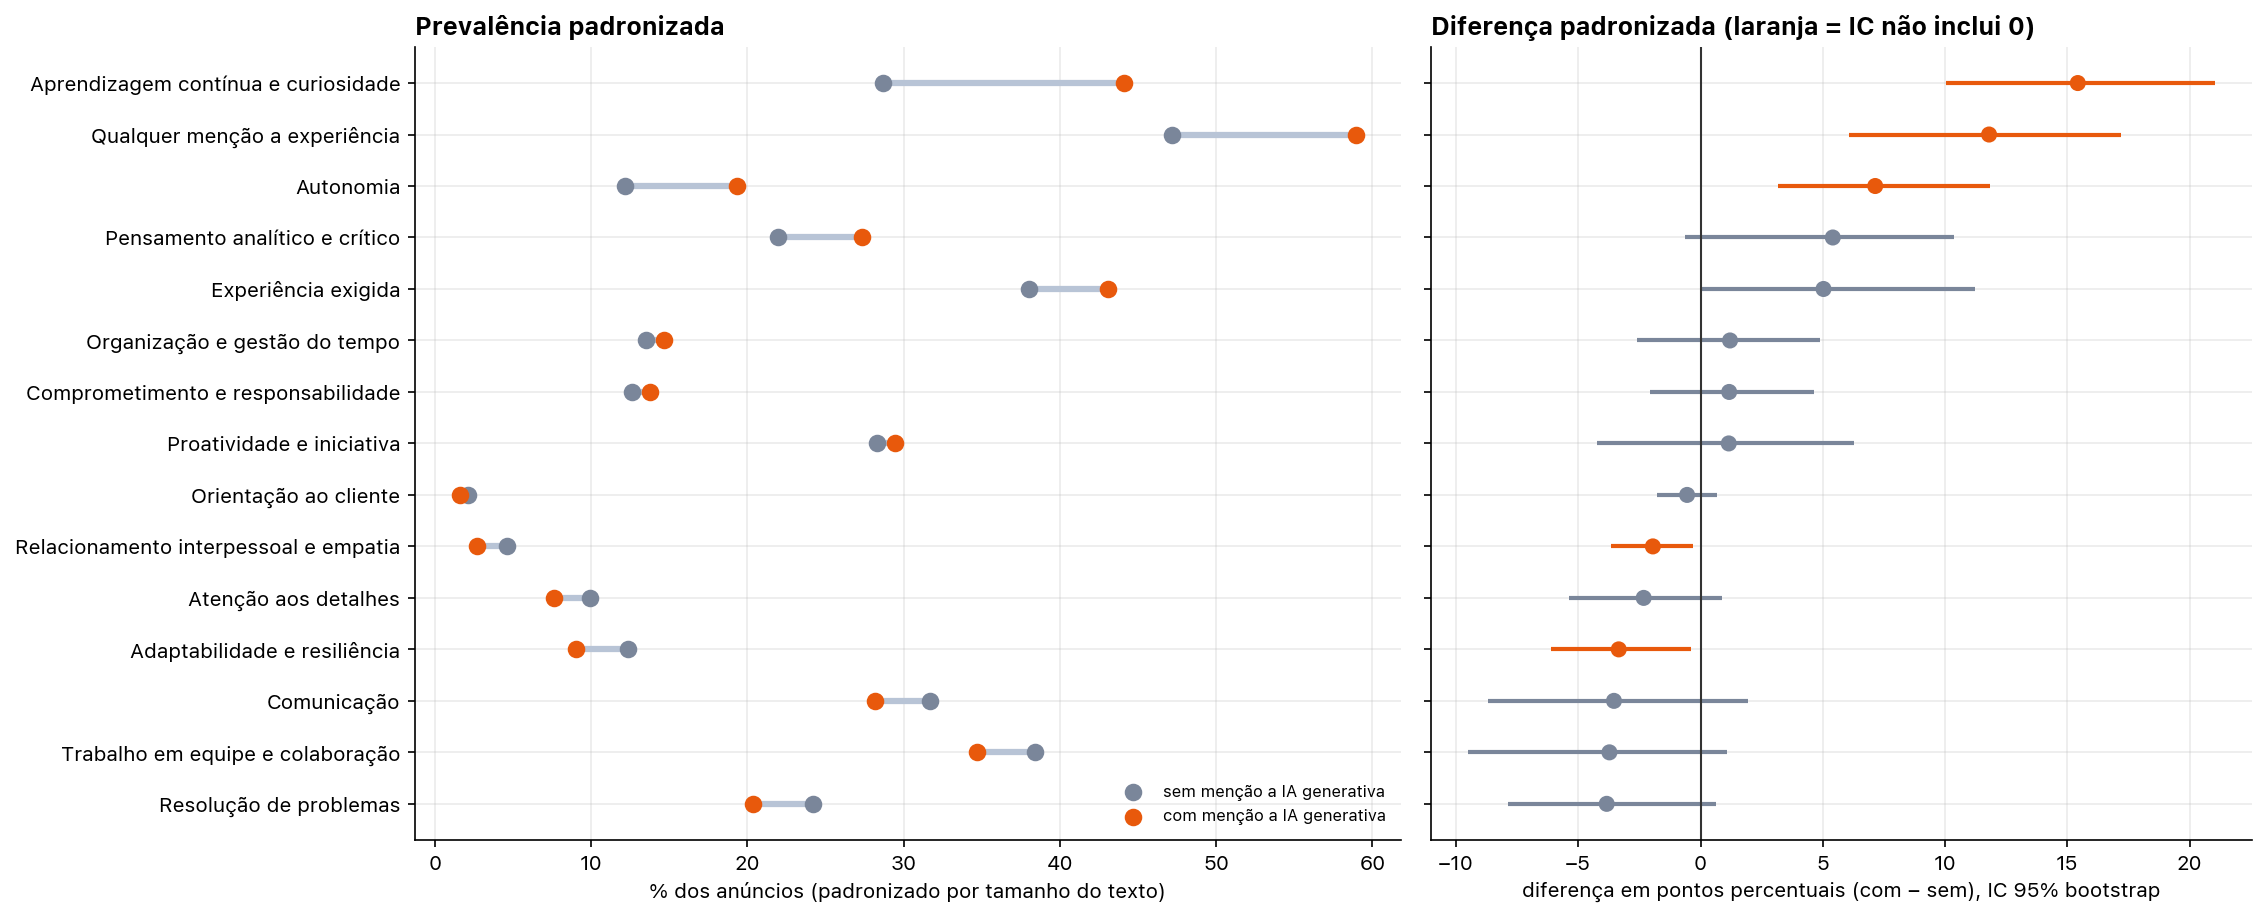

,bruto_sem,bruto_com,pad_sem,pad_com,dif_pad,dif_lo,dif_hi
variavel,,,,,,,
Resolução de problemas,23.7,23.3,24.2,20.3,-3.8,-7.9,0.6
Trabalho em equipe e colaboração,37.7,39.8,38.4,34.7,-3.7,-9.5,1.1
Comunicação,31.2,29.7,31.7,28.2,-3.5,-8.7,1.9
Adaptabilidade e resiliência,11.9,11.5,12.3,9.0,-3.3,-6.1,-0.4
Atenção aos detalhes,9.7,8.4,10.0,7.6,-2.3,-5.4,0.9
Relacionamento interpessoal e empatia,4.5,2.6,4.6,2.7,-1.9,-3.6,-0.3
Orientação ao cliente,2.1,1.9,2.1,1.6,-0.5,-1.8,0.7
Proatividade e iniciativa,27.7,32.4,28.3,29.5,1.2,-4.2,6.3
Comprometimento e responsabilidade,12.3,17.7,12.6,13.8,1.2,-2.1,4.7


In [8]:
VARS = [(f"c_{k}", ROT[k]) for k in CHAVES] + [("exp_obrigatoria", "Experiência exigida"), ("exp_qualquer", "Qualquer menção a experiência")]
rows = []
for col, nome in VARS:
    pt, pc = L.padronizar_por_quartil(dev, col, "genai")
    lo, hi = L.bootstrap_dif_padronizada(dev, col, "genai", n_boot=300)
    rows.append({"variavel": nome, "bruto_com": 100 * dev[dev.genai][col].mean(), "bruto_sem": 100 * dev[~dev.genai][col].mean(),
                 "pad_com": pt, "pad_sem": pc, "dif_pad": pt - pc, "dif_lo": lo, "dif_hi": hi})
cmp_ = pd.DataFrame(rows).sort_values("dif_pad")
cmp_["sig"] = (cmp_["dif_lo"] > 0) | (cmp_["dif_hi"] < 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]}, sharey=True)
y = np.arange(len(cmp_))
axes[0].hlines(y, cmp_["pad_sem"], cmp_["pad_com"], color="#B8C4D6", lw=3)
axes[0].scatter(cmp_["pad_sem"], y, color="#7A869A", s=55, label="sem menção a IA generativa", zorder=3)
axes[0].scatter(cmp_["pad_com"], y, color="#E8590C", s=55, label="com menção a IA generativa", zorder=3)
axes[0].set_yticks(y); axes[0].set_yticklabels(cmp_["variavel"]); axes[0].set_xlabel("% dos anúncios (padronizado por tamanho do texto)")
axes[0].set_title("Prevalência padronizada"); axes[0].legend(loc="lower right", fontsize=8)
cor = np.where(cmp_["sig"], "#E8590C", "#7A869A")
axes[1].hlines(y, cmp_["dif_lo"], cmp_["dif_hi"], color=cor, lw=2)
axes[1].scatter(cmp_["dif_pad"], y, color=cor, s=45, zorder=3); axes[1].axvline(0, color="#333", lw=1)
axes[1].set_xlabel("diferença em pontos percentuais (com − sem), IC 95% bootstrap"); axes[1].set_title("Diferença padronizada (laranja = IC não inclui 0)")
L.salvar(fig, "04_com_sem_ia"); plt.show()
cmp_.to_csv(L.BASE / "tabela_04_com_sem_ia.csv", index=False)
display(cmp_.round(1).set_index("variavel")[["bruto_sem", "bruto_com", "pad_sem", "pad_com", "dif_pad", "dif_lo", "dif_hi"]].style.format("{:.1f}").set_caption("% de anúncios; padronizado = ajustado por quartil de tamanho"))

## 5. Robustez: regressão logística com controles
Para as competências mais frequentes, ajusta-se `competência ~ IA generativa + área + nível + portal + log(tamanho do texto)` (Estágio e Júnior apenas).
O valor reportado é a **razão de chances (OR)** da menção à IA generativa. OR > 1 indica associação positiva, mantidas as demais variáveis constantes. **Não é efeito causal.**

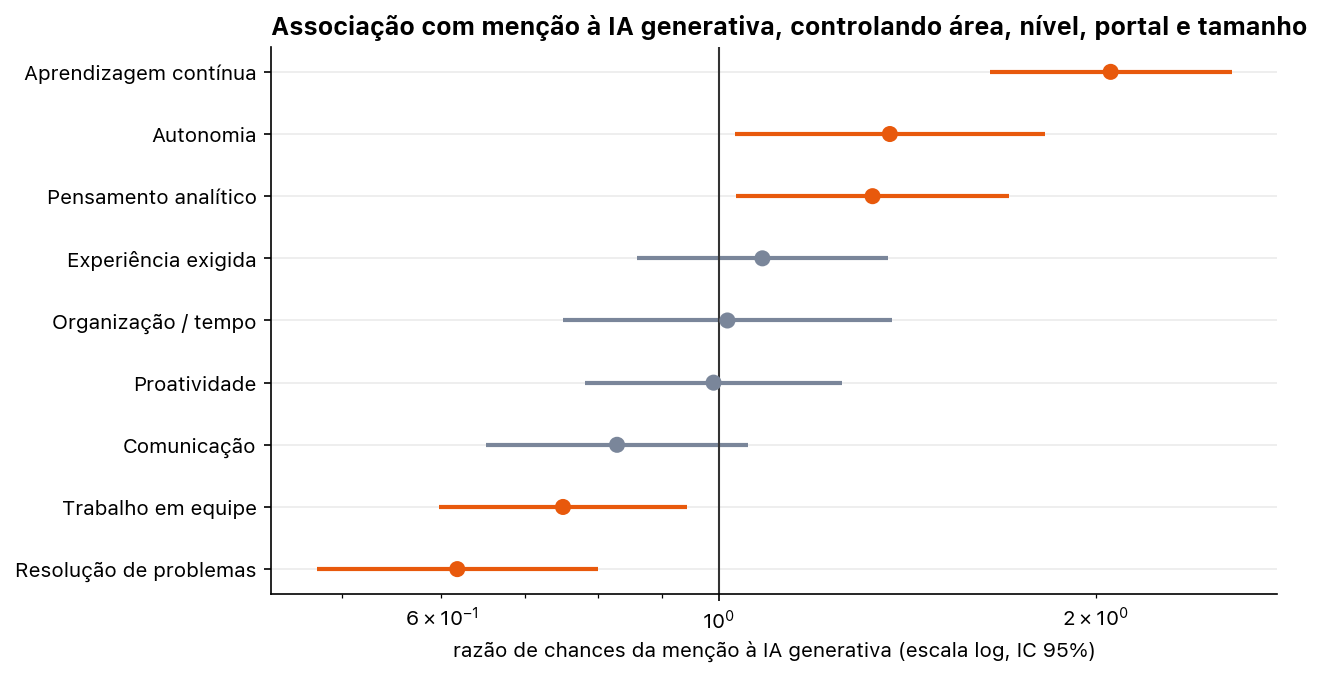

variavel,OR,lo,hi,p,n
Resolução de problemas,0.62,0.48,0.80,0.000,3642
Trabalho em equipe,0.75,0.60,0.94,0.014,3642
Comunicação,0.83,0.65,1.05,0.126,3642
Proatividade,0.99,0.78,1.25,0.934,3642
Organização / tempo,1.02,0.75,1.37,0.920,3642
Experiência exigida,1.08,0.86,1.36,0.497,3642
Pensamento analítico,1.33,1.03,1.71,0.027,3642
Autonomia,1.37,1.03,1.82,0.030,3642
Aprendizagem contínua,2.06,1.65,2.57,0.000,3642


In [9]:
reg = dev[dev.nivel.isin(L.NIVEIS_PRINCIPAIS)].copy()
top_f = reg["fonte"].value_counts().head(4).index
reg["fonte_agr"] = reg["fonte"].where(reg["fonte"].isin(top_f), "outros")
reg["area_s"] = reg["area"].astype(str); reg["genai_i"] = reg["genai"].astype(int); reg["log_tam"] = np.log(reg["n_chars_aparado"])
desf = [("comunicacao", "Comunicação"), ("trabalho_equipe", "Trabalho em equipe"), ("resolucao_problemas", "Resolução de problemas"),
        ("pensamento_analitico", "Pensamento analítico"), ("proatividade", "Proatividade"), ("aprendizagem_continua", "Aprendizagem contínua"),
        ("autonomia", "Autonomia"), ("organizacao_tempo", "Organização / tempo")]
res = []
for k, nome in desf + [("exp_obrigatoria", "Experiência exigida")]:
    col = k if k.startswith("exp_") else f"c_{k}"
    reg["y"] = reg[col].astype(int)
    try:
        m = smf.logit("y ~ genai_i + C(area_s) + C(nivel) + C(fonte_agr) + log_tam", data=reg).fit(disp=0, maxiter=200)
        b, ci = m.params["genai_i"], m.conf_int().loc["genai_i"]
        res.append({"variavel": nome, "OR": np.exp(b), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": m.pvalues["genai_i"], "n": int(m.nobs)})
    except Exception as e:
        res.append({"variavel": nome, "OR": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan, "n": 0})
rg = pd.DataFrame(res).sort_values("OR")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
y = np.arange(len(rg)); cor = np.where((rg["lo"] > 1) | (rg["hi"] < 1), "#E8590C", "#7A869A")
ax.hlines(y, rg["lo"], rg["hi"], color=cor, lw=2); ax.scatter(rg["OR"], y, color=cor, zorder=3, s=45); ax.axvline(1, color="#333", lw=1)
ax.set_yticks(y); ax.set_yticklabels(rg["variavel"]); ax.set_xscale("log"); ax.set_xlabel("razão de chances da menção à IA generativa (escala log, IC 95%)")
ax.set_title("Associação com menção à IA generativa, controlando área, nível, portal e tamanho")
L.salvar(fig, "04_regressao_logistica"); plt.show()
rg.to_csv(L.BASE / "tabela_04_regressao.csv", index=False)
display(rg.round(3).style.hide(axis="index").format({"OR": "{:.2f}", "lo": "{:.2f}", "hi": "{:.2f}", "p": "{:.3f}"}))

## 6. Sensibilidade da definição de "menção à IA generativa"
(a) Incluir a categoria **"Agentes de IA & RAG"** da taxonomia; (b) comparar a taxonomia com uma busca textual própria (sem a sigla "IA" isolada).

In [10]:
a = dev.genai.mean() * 100; b = dev.genai_ext.mean() * 100
txt = dev["tf"].str.contains(RX_SEM_BARE)
print(f"(a) Taxonomia (Copilots + LLMs): {a:.1f}% | com Agentes de IA & RAG: {b:.1f}%")
kap = cohen_kappa_score(dev.genai, txt)
print(f"(b) Busca textual própria: {txt.mean() * 100:.1f}% | concordância com a taxonomia (kappa de Cohen): {kap:.2f}")
display(pd.crosstab(dev.genai.map({True: "taxonomia: com IA", False: "taxonomia: sem IA"}), txt.map({True: "texto: termo de IA", False: "texto: sem termo"})))

(a) Taxonomia (Copilots + LLMs): 11.2% | com Agentes de IA & RAG: 11.5%
(b) Busca textual própria: 13.2% | concordância com a taxonomia (kappa de Cohen): 0.89


tf,texto: sem termo,texto: termo de IA
genai,,
taxonomia: com IA,5,412
taxonomia: sem IA,3241,80


## 7. Números para o texto

In [11]:
est = dev[dev.nivel == "Estágio"]; jun = dev[dev.nivel == "Júnior"]
Markdown(f"""
- Em **Desenvolvimento e dados** (sem a área IA, n = {len(dev):,}), **{dev.genai.mean():.1%}** dos anúncios mencionam IA generativa ({dev.genai.sum()} anúncios): {est.genai.mean():.1%} no Estágio (n = {len(est):,}) e {jun.genai.mean():.1%} no Júnior (n = {len(jun):,}).
- Nos grupos **Suporte e infraestrutura** e **Outras**, os valores são {df[df.grupo == L.G_SUP].genai.mean():.1%} e {df[df.grupo == L.G_OUT].genai.mean():.1%}.
- Segundo a pré-classificação automática, {d1['Requisito profissional'] / len(ia):.0%} dos trechos aparecem como requisito, {d1['Atividade prevista'] / len(ia):.0%} como atividade e {d1['Contexto organizacional'] / len(ia):.0%} como contexto organizacional; {d1['Indefinido (revisar)'] / len(ia):.0%} ficam para revisão. **Substituir pelos números da classificação manual.**
- {ia.assoc_validacao_automatica.mean():.0%} dos trechos têm palavras de revisão/validação por perto (**a confirmar manualmente**).
""")


- Em **Desenvolvimento e dados** (sem a área IA, n = 3,738), **11.2%** dos anúncios mencionam IA generativa (417 anúncios): 8.1% no Estágio (n = 1,043) e 12.7% no Júnior (n = 2,599).
- Nos grupos **Suporte e infraestrutura** e **Outras**, os valores são 1.6% e 4.6%.
- Segundo a pré-classificação automática, 37% dos trechos aparecem como requisito, 26% como atividade e 8% como contexto organizacional; 28% ficam para revisão. **Substituir pelos números da classificação manual.**
- 21% dos trechos têm palavras de revisão/validação por perto (**a confirmar manualmente**).


### Como interpretar
- A menção explícita à IA generativa é **minoritária** em Desenvolvimento e dados e **rara** nos demais grupos. Isso é compatível tanto com "ainda é pouco exigida" quanto com "é esperada de forma implícita": a base não permite distinguir (e o artigo já registra essa ressalva).
- A diferença entre portais mostra que a prevalência depende do **canal**; relate-a com cuidado e mostre a sensibilidade (notebook `06`).
- **Duas formas de controle, dois retratos.** Só padronizando pelo tamanho do texto, comunicação, resolução de problemas e trabalho em equipe **não diferem** entre anúncios com e sem IA (ICs incluem zero). Na regressão, que também controla **área, nível e portal**, a razão de chances de *resolução de problemas* cai abaixo de 1. A diferença entre as duas leituras indica que parte do efeito aparente vem da **composição por área** (por exemplo, Fullstack e Data concentram as menções). Relatar as duas.
- O que se sustenta nas duas abordagens: anúncios com menção à IA têm mais **aprendizagem contínua e curiosidade** e mais **autonomia**; o pensamento analítico sobe só na regressão.
- As diferenças **com × sem IA** são de **associação**. Anúncios mais "modernos" ou de empresas de produto tendem a pedir várias coisas ao mesmo tempo; isso não é efeito da IA.
- A **planilha de trechos** é o insumo real para o objetivo (iv): ela deve ser classificada por duas leitoras, com cálculo de concordância (kappa) antes de se publicar proporções de R/A/C.